In [1]:
%load_ext autoreload
%autoreload 2

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score

import sys
import os
cartella_src = os.path.abspath(os.path.join(os.getcwd(), '..', 'src'))

if cartella_src not in sys.path:
    sys.path.insert(0, cartella_src)
# 1. Importiamo i moduli custom dai file fisici
from Preprocessor import FullPipeline
from Regression.LinearRegression import LinearRegression

# 2. Caricamento e Preprocessing
print("Inizializzazione della FullPipeline...")
path_al_dataset = '../Dataset/AB_NYC_2019.csv'

pipeline = FullPipeline(path_al_dataset)
df_clean = pipeline.transform()
print(f"Dataset pulito. Shape: {df_clean.shape[0]} x {df_clean.shape[1]}")

# 3. Split e Scaling
X = df_clean.drop(columns=['log_price'])
y = df_clean['log_price']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns)

# 4. Addestramento del Modello (es. Lasso)
print("Addestramento del modello in corso...")
# Puoi testare penalty='l1' (Lasso), penalty='l2' (Ridge), o penalty=None (OLS standard)
model = LinearRegression(penalty='l1', alpha=0.01) 
model.fit(X_train_scaled, y_train)

# 5. Previsione
y_pred_log = model.predict(X_test_scaled)

# 6. Valutazione Economica (riconversione da log a dollari)
y_test_dollars = np.expm1(y_test)
y_pred_dollars = np.expm1(y_pred_log)

rmse = np.sqrt(mean_squared_error(y_test_dollars, y_pred_dollars))
r2 = r2_score(y_test, y_pred_log)

print(f"\n--- Risultati ---")
print(f"R^2 Score: {r2:.4f}")
print(f"RMSE (Errore Medio): ${rmse:.2f}")

# 7. Analisi dei Coefficienti
coef_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Coefficiente': model.coefficients
})

# Filtriamo solo le variabili che la Lasso ha mantenuto attive
driver_attivi = coef_df[coef_df['Coefficiente'] != 0].copy()
driver_attivi['Impatto'] = driver_attivi['Coefficiente'].abs()
driver_attivi = driver_attivi.sort_values(by='Impatto', ascending=False)

print("\n--- Top 10 Primary Drivers ---")
print(driver_attivi[['Feature', 'Coefficiente']].head(10))

Inizializzazione della FullPipeline...
Dataset pulito. Shape: 48869 x 13
Addestramento del modello in corso...

--- Risultati ---
R^2 Score: 0.4743
RMSE (Errore Medio): $105.83

--- Top 10 Primary Drivers ---
                              Feature  Coefficiente
7                   room_type_ordinal      0.384798
9       neighbourhood_group_Manhattan      0.159503
4                    availability_365      0.076653
10         neighbourhood_group_Queens     -0.031069
0                      minimum_nights     -0.027375
1                   number_of_reviews     -0.015417
2                   reviews_per_month     -0.011515
11  neighbourhood_group_Staten Island     -0.011484
6                host_is_professional     -0.004211
3      calculated_host_listings_count      0.003607


Si nota che la variabile che fa aumentare principalmente il prezzo è il tipo di stanza. Il coefficiente corrispondente è di 0.384798, questo significa che exp(0.384798)-1= 0.468, cioè che questa variabile può far aumentare il prezzo del 46.8%
Un discorso simile lo si applica per neighbourhood_group_Manhattan: lo stare vicino al centro di Manhattan auamenta il prezzo del 17.2%

R^2 è basso per la natura del dataset. Infatti questo non contiene informazioni circa la grandezza delle stanze e i vari servizi offerti con la stanza (piscina, tipologia di arredamento, etc.)


In [5]:
# Importa il nuovo modulo
from Regression.TreeRegression import TreeRegression

print("Addestramento del Random Forest in corso... (potrebbe richiedere qualche secondo)")
# Inizializziamo con 100 alberi. Limitiamo la profondità a 20 per prevenire 
# che il modello impari a memoria il dataset di training (overfitting)
tree_model = TreeRegression(n_estimators=100, max_depth=20)

# Utilizziamo gli stessi dati già preparati precedentemente
tree_model.fit(X_train_scaled, y_train)

# Previsione e Valutazione
y_pred_log_tree = tree_model.predict(X_test_scaled)

# Riconversione in dollari
y_test_dollars = np.expm1(y_test)
y_pred_dollars_tree = np.expm1(y_pred_log_tree)

rmse_tree = np.sqrt(mean_squared_error(y_test_dollars, y_pred_dollars_tree))
r2_tree = r2_score(y_test, y_pred_log_tree)

print(f"\n--- Risultati Random Forest ---")
print(f"R^2 Score: {r2_tree:.4f}")
print(f"RMSE (Errore Medio): ${rmse_tree:.2f}")

# Analisi dell'importanza delle feature
importanza = pd.DataFrame({
    'Feature': X_train.columns,
    'Importanza': tree_model.feature_importances
})
importanza = importanza.sort_values(by='Importanza', ascending=False)

print("\n--- Feature Importances (Top 5) ---")
print(importanza.head(5))

Addestramento del Random Forest in corso... (potrebbe richiedere qualche secondo)

--- Risultati Random Forest ---
R^2 Score: 0.5294
RMSE (Errore Medio): $97.79

--- Feature Importances (Top 5) ---
                         Feature  Importanza
7              room_type_ordinal    0.481447
2              reviews_per_month    0.100739
9  neighbourhood_group_Manhattan    0.077797
1              number_of_reviews    0.071441
0                 minimum_nights    0.070339


In [6]:
# Importa la nuova pipeline spaziale e il modello ad albero
from Preprocessor import TreePipeline
from Regression.TreeRegression import TreeRegression

print("1. Inizializzazione TreePipeline (con Coordinate Spaziali)...")
tree_pipeline = TreePipeline('../Dataset/AB_NYC_2019.csv')
df_tree = tree_pipeline.transform()

# 2. Split Feature/Target
X_tree = df_tree.drop(columns=['log_price'])
y_tree = df_tree['log_price']

# 3. Data Split (Nessuno StandardScaler applicato)
X_train_tree, X_test_tree, y_train_tree, y_test_tree = train_test_split(
    X_tree, y_tree, test_size=0.2, random_state=42
)

print("2. Addestramento Random Forest sui dati grezzi...")
tree_model = TreeRegression(n_estimators=100, max_depth=20)
tree_model.fit(X_train_tree, y_train_tree)

# 4. Previsioni e Riconversione
y_pred_log_tree = tree_model.predict(X_test_tree)
y_test_dollars = np.expm1(y_test_tree)
y_pred_dollars_tree = np.expm1(y_pred_log_tree)

# 5. Metriche
rmse_tree = np.sqrt(mean_squared_error(y_test_dollars, y_pred_dollars_tree))
r2_tree = r2_score(y_test_tree, y_pred_log_tree)

print(f"\n--- Risultati Random Forest (TreePipeline) ---")
print(f"R^2 Score: {r2_tree:.4f}")
print(f"RMSE: ${rmse_tree:.2f}")

# 6. Analisi Importanza
importanza_tree = pd.DataFrame({
    'Feature': X_train_tree.columns,
    'Importanza': tree_model.feature_importances
}).sort_values(by='Importanza', ascending=False)

print("\n--- Feature Importances (Top 7) ---")
print(importanza_tree.head(7))

1. Inizializzazione TreePipeline (con Coordinate Spaziali)...
2. Addestramento Random Forest sui dati grezzi...

--- Risultati Random Forest (TreePipeline) ---
R^2 Score: 0.6282
RMSE: $90.91

--- Feature Importances (Top 7) ---
              Feature  Importanza
9   room_type_ordinal    0.428503
1           longitude    0.147103
0            latitude    0.140749
4   reviews_per_month    0.050528
2      minimum_nights    0.048616
3   number_of_reviews    0.039325
7  availability_ratio    0.038333


La random forest ottiene riusltati migliori rispetto alla linear regression.

Il valore R quadro sale a 0.6282 utilizzando un dataset che contiene longitudine e latitudine in modo separato. 

Rimane evidente come la feature che causa il maggiore incremento del prezzo è la tipologia della stanza, seguito dalla posizione. Un altro indice importante si rivela essere il numero di recensioni per mese e totali, così anche come il fattore di notti minime.


OLS:   {'MSE': 0.2342, 'MAE': 0.3642, 'R-squared': 0.4801}
Ridge: {'MSE': 0.2342, 'MAE': 0.3642, 'R-squared': 0.4801}
Feature Selection completata: mantenute 5 variabili su 12.
Lasso: {'MSE': 0.2687, 'MAE': 0.3961, 'R-squared': 0.4036}
RF:    {'MSE': 0.1675, 'MAE': 0.3027, 'R-squared': 0.6282}
Calcolo della Validation Curve in corso...


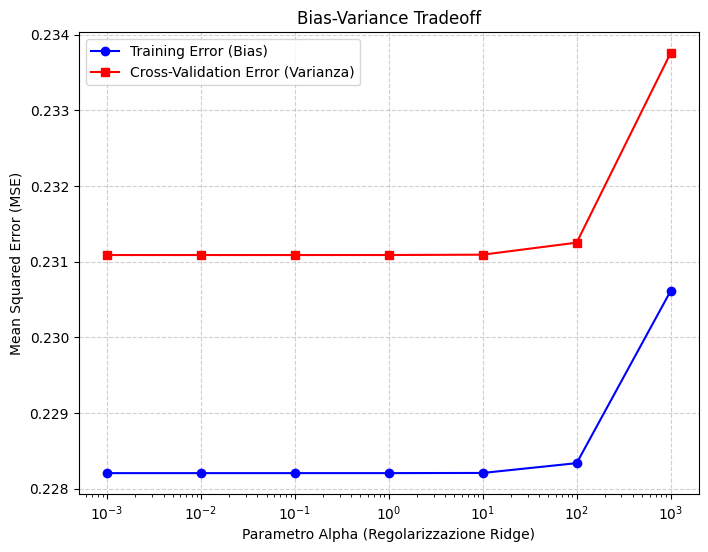

In [7]:
from Preprocessor import FullPipeline, TreePipeline
from MainRegression import Regression
from sklearn.model_selection import train_test_split

# --- 1. CARICA E PREPROCESSA ---

# Per i modelli lineari
pipeline_linear = FullPipeline("../Dataset/AB_NYC_2019.csv")
df_linear = pipeline_linear.transform()

# Per il Random Forest
pipeline_tree = TreePipeline("../Dataset/AB_NYC_2019.csv")
df_tree = pipeline_tree.transform()

# --- 2. ISTANZIA LA CLASSE REGRESSION ---

reg_linear = Regression(df_linear, target_column='log_price')
reg_tree   = Regression(df_tree,   target_column='log_price')

# --- 3. TESTA I MODELLI ---

# OLS (nessuna penalità)
metrics_ols = reg_linear.evaluate(model_type='linear', penalty=None)
print("OLS:  ", metrics_ols)

# Ridge
metrics_ridge = reg_linear.evaluate(model_type='linear', penalty='l2', alpha=1.0)
print("Ridge:", metrics_ridge)

# Lasso con feature selection
metrics_lasso = reg_linear.evaluate(model_type='linear', penalty='l1', alpha=0.01,
                                    use_feature_selection=True)
print("Lasso:", metrics_lasso)

# Random Forest
metrics_rf = reg_tree.evaluate(model_type='tree', n_estimators=100, max_depth=20)
print("RF:   ", metrics_rf)

# --- 4. BIAS-VARIANCE TRADEOFF ---
reg_linear.analyze_bias_variance()